Stage 1 — Dataset quality: 
Class distribution, empty labels, annotation validation, duplicate detection.

In [1]:
from pathlib import Path

In [2]:
from pathlib import Path

# Dataset path relative to the notebooks directory
DATASET_PATH = Path("../data/RDD_SPLIT").resolve()

# Verify dataset exists
assert DATASET_PATH.is_dir(), f"Dataset not found: {DATASET_PATH}"

print(f"Dataset path: {DATASET_PATH}")

Dataset path: C:\Users\Dinuka\Documents\GitHub\RoadLens\ml\c1\data\RDD_SPLIT


In [3]:

import pandas as pd

dataset_stats = []

for split in ["train", "val", "test"]:
    images_dir = DATASET_PATH / split / "images"
    labels_dir = DATASET_PATH / split / "labels"

    image_files = [
        p for p in images_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    label_files = list(labels_dir.glob("*.txt"))

    dataset_stats.append({
        "Split": split,
        "Images": len(image_files),
        "Label Files": len(label_files),
        "Images Without Label Files": len(
            {p.stem for p in image_files}
            - {p.stem for p in label_files}
        )
    })

df_stats = pd.DataFrame(dataset_stats)
display(df_stats)


,Split,Images,Label Files,Images Without Label Files
0,train,26869,26869,0
1,val,5758,5758,0
2,test,5758,5758,0


## RDD2022 class-name mapping

The official RDD2022 documentation defines four core damage categories: D00 longitudinal crack, D10 transverse crack, D20 alligator crack, and D40 pothole. This local YOLO split contains five numeric classes, so class 4 is documented as the conversion-specific `Other corruption` category used by common five-class YOLO conversions. It should not be treated as one of the four core RDD2022 evaluation classes without checking the exact conversion provenance.

Sources: [RDD2022 paper](https://arxiv.org/abs/2209.08538), [official RoadDamageDetector repository](https://github.com/sekilab/RoadDamageDetector), and [CRDDC 2022 dataset record](https://figshare.com/articles/dataset/RDD2022_-_The_multi-national_Road_Damage_Dataset_released_through_CRDDC_2022/21431547).


In [ ]:
CLASS_NAMES = {
    0: "Longitudinal crack (D00)",
    1: "Transverse crack (D10)",
    2: "Alligator crack (D20)",
    3: "Pothole (D40)",
    4: "Other corruption (conversion-specific)",
}

class_name_table = pd.DataFrame(
    [{"Class ID": class_id, "Class Name": name} for class_id, name in CLASS_NAMES.items()]
).set_index("Class ID")

display(class_name_table)

# Use descriptive names in the class-distribution table while retaining numeric IDs.
df_classes_named = df_classes.rename(index=CLASS_NAMES)
display(df_classes_named)


In [4]:

from collections import Counter
import pandas as pd

class_counts = {}
empty_labels = {}

for split in ["train", "val", "test"]:
    labels_dir = DATASET_PATH / split / "labels"
    counts = Counter()
    empty_count = 0

    for label_path in labels_dir.glob("*.txt"):
        lines = label_path.read_text(encoding="utf-8").splitlines()

        if not lines:
            empty_count += 1

        for line in lines:
            parts = line.strip().split()
            if parts:
                class_id = int(parts[0])
                counts[class_id] += 1

    class_counts[split] = counts
    empty_labels[split] = empty_count

all_classes = sorted(
    set().union(*(counts.keys() for counts in class_counts.values()))
)

df_classes = pd.DataFrame({
    split: [class_counts[split][cls] for cls in all_classes]
    for split in ["train", "val", "test"]
}, index=all_classes)

df_classes.index.name = "Class ID"
df_classes["Total"] = df_classes.sum(axis=1)

display(df_classes)

print("\nEmpty annotation files:")
print(empty_labels)


,train,val,test,Total
Class ID,,,,
0,18201,3890,3925,26016
1,8386,1769,1675,11830
2,7527,1553,1537,10617
3,7554,1564,1587,10705
4,4628,965,951,6544



Empty annotation files:
{'train': 8097, 'val': 1837, 'test': 1790}


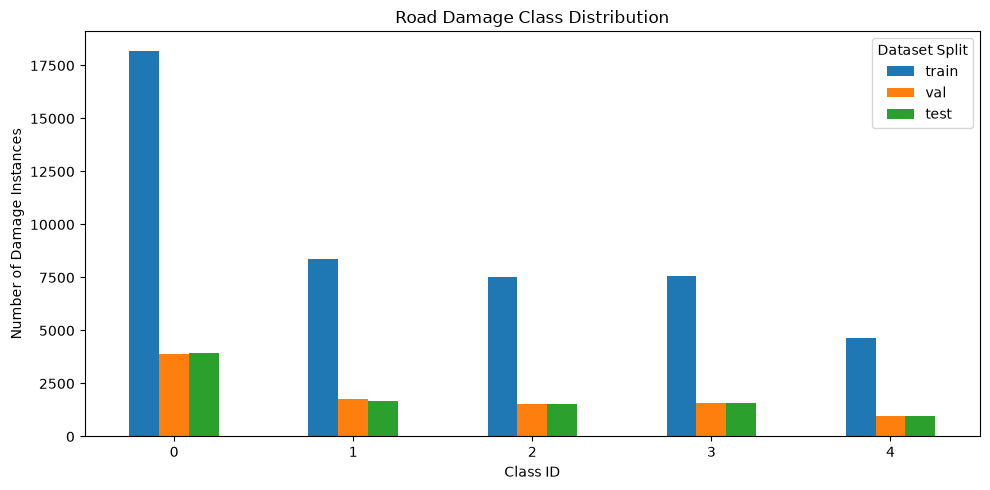

In [5]:

import matplotlib.pyplot as plt

ax = df_classes[["train", "val", "test"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Road Damage Class Distribution")
plt.xlabel("Class ID")
plt.ylabel("Number of Damage Instances")
plt.xticks(rotation=0)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()


Stage 2 — Visual characteristics: 
Image resolutions, bounding-box statistics, visual samples and image quality.

In [6]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}
SPLITS = ["train", "val", "test"]

def image_paths(split):
    return sorted(
        path for path in (DATASET_PATH / split / "images").iterdir()
        if path.suffix.lower() in IMAGE_EXTENSIONS
    )

def load_image(path):
    image = mpimg.imread(path)
    if image.ndim == 2:
        image = np.repeat(image[..., None], 3, axis=2)
    return image[..., :3] if image.shape[-1] == 4 else image

print("Stage 2 helpers loaded.")


Stage 2 helpers loaded.


In [7]:
resolution_rows = []
for split in SPLITS:
    for path in image_paths(split):
        image = load_image(path)
        height, width = image.shape[:2]
        resolution_rows.append({
            "Split": split,
            "Width": width,
            "Height": height,
            "Aspect Ratio": width / height,
            "Pixels (M)": width * height / 1_000_000,
        })

df_resolutions = pd.DataFrame(resolution_rows)
display(df_resolutions.groupby("Split")[["Width", "Height", "Aspect Ratio", "Pixels (M)"]].agg(["min", "median", "max"]).round(3))

resolution_counts = (
    df_resolutions.groupby(["Split", "Width", "Height"])
    .size()
    .reset_index(name="Images")
    .sort_values(["Split", "Images"], ascending=[True, False])
)
display(resolution_counts.groupby("Split").head(10))


Width              Height              Aspect Ratio                \
        min median   max    min median   max          min median    max   
Split                                                                     
test    512  640.0  4040    512  640.0  2044          1.0    1.0  1.985   
train   512  640.0  4040    512  640.0  2044          1.0    1.0  1.985   
val     512  640.0  4040    512  640.0  2044          1.0    1.0  1.985   

      Pixels (M)                
             min median    max  
Split                           
test       0.262   0.41  8.221  
train      0.262   0.41  8.221  
val        0.262   0.41  8.221

,Split,Width,Height,Images
2,test,600,600,1921
4,test,720,720,1166
3,test,640,640,753
0,test,512,512,682
9,test,4040,2035,631
7,test,3643,2041,435
8,test,3650,2044,131
5,test,1024,1024,18
1,test,540,540,15
6,test,1080,1080,6


In [8]:
bbox_rows = []
invalid_annotations = []
for split in SPLITS:
    for label_path in sorted((DATASET_PATH / split / "labels").glob("*.txt")):
        for line_number, line in enumerate(label_path.read_text(encoding="utf-8").splitlines(), 1):
            parts = line.strip().split()
            if not parts:
                continue
            try:
                class_id, x_center, y_center, box_width, box_height = map(float, parts[:5])
            except (ValueError, IndexError):
                invalid_annotations.append((split, label_path.name, line_number, line))
                continue
            if not (0 <= x_center <= 1 and 0 <= y_center <= 1 and 0 < box_width <= 1 and 0 < box_height <= 1):
                invalid_annotations.append((split, label_path.name, line_number, line))
                continue
            bbox_rows.append({
                "Split": split,
                "Class ID": int(class_id),
                "Width": box_width,
                "Height": box_height,
                "Area": box_width * box_height,
                "Image": label_path.stem,
            })

df_bboxes = pd.DataFrame(bbox_rows)
display(df_bboxes.groupby(["Split", "Class ID"])[["Width", "Height", "Area"]].agg(["count", "mean", "median", "min", "max"]).round(4))
print(f"Valid bounding boxes: {len(df_bboxes):,}")
print(f"Invalid bounding-box rows: {len(invalid_annotations):,}")


Width                                 Height                  \
                count    mean  median     min     max  count    mean  median   
Split Class ID                                                                 
test  0          3925  0.1066  0.0812  0.0025  0.9980   3925  0.1959  0.1469   
      1          1675  0.2995  0.2383  0.0114  0.9980   1675  0.0573  0.0467   
      2          1537  0.3846  0.3250  0.0131  0.9983   1537  0.2626  0.2417   
      3          1587  0.2534  0.1817  0.0033  0.9983   1587  0.1839  0.1348   
      4           951  0.1248  0.0933  0.0050  0.9847    951  0.0774  0.0562   
train 0         18201  0.1027  0.0764  0.0019  0.9980  18201  0.1893  0.1406   
      1          8386  0.2883  0.2359  0.0074  0.9980   8386  0.0558  0.0450   
      2          7526  0.3909  0.3283  0.0088  0.9990   7526  0.2643  0.2421   
      3          7554  0.2541  0.1778  0.0017  0.9983   7554  0.1822  0.1333   
      4          4628  0.1273  0.0917  0.0051  0.9972   4628  0.0786  0.0569   
val   0          3890  0.1052  0.0781  0.0025  0.9980   3890  0.1906  0.1386   
      1          1769  0.2874  0.2333  0.0106  0.9980   1769  0.0568  0.0450   
      2          1553  0.3849  0.3233  0.0165  0.9990   1553  0.2644  0.2467   
      3          1564  0.2618  0.1915  0.0293  0.9980   1564  0.1877  0.1385   
      4           965  0.1261  0.0986  0.0058  0.8542    965  0.0799  0.0617   

                                 Area                                  
                   min     max  count    mean  median     min     max  
Split Class ID                                                         
test  0         0.0054  0.9980   3925  0.0274  0.0128  0.0000  0.4842  
      1         0.0037  0.5898   1675  0.0229  0.0112  0.0000  0.5887  
      2         0.0148  0.9980   1537  0.1210  0.0804  0.0003  0.8928  
      3         0.0050  0.9980   1587  0.0639  0.0258  0.0000  0.7349  
      4         0.0043  0.8574    951  0.0149  0.0051  0.0000  0.3310  
train 0         0.0041  0.9980  18201  0.0260  0.0115  0.0000  0.6706  
      1         0.0029  0.6738   8386  0.0210  0.0107  0.0000  0.6725  
      2         0.0067  0.9980   7526  0.1220  0.0818  0.0001  0.9233  
      3         0.0017  0.9980   7554  0.0650  0.0245  0.0000  0.8246  
      4         0.0037  0.7949   4628  0.0155  0.0053  0.0000  0.3871  
val   0         0.0061  0.9980   3890  0.0270  0.0116  0.0000  0.5593  
      1         0.0021  0.4023   1769  0.0214  0.0105  0.0000  0.3481  
      2         0.0269  0.9961   1553  0.1214  0.0819  0.0004  0.9408  
      3         0.0033  0.9980   1564  0.0696  0.0274  0.0003  0.7602  
      4         0.0064  0.6777    965  0.0150  0.0058  0.0001  0.2407

Valid bounding boxes: 65,711
Invalid bounding-box rows: 1


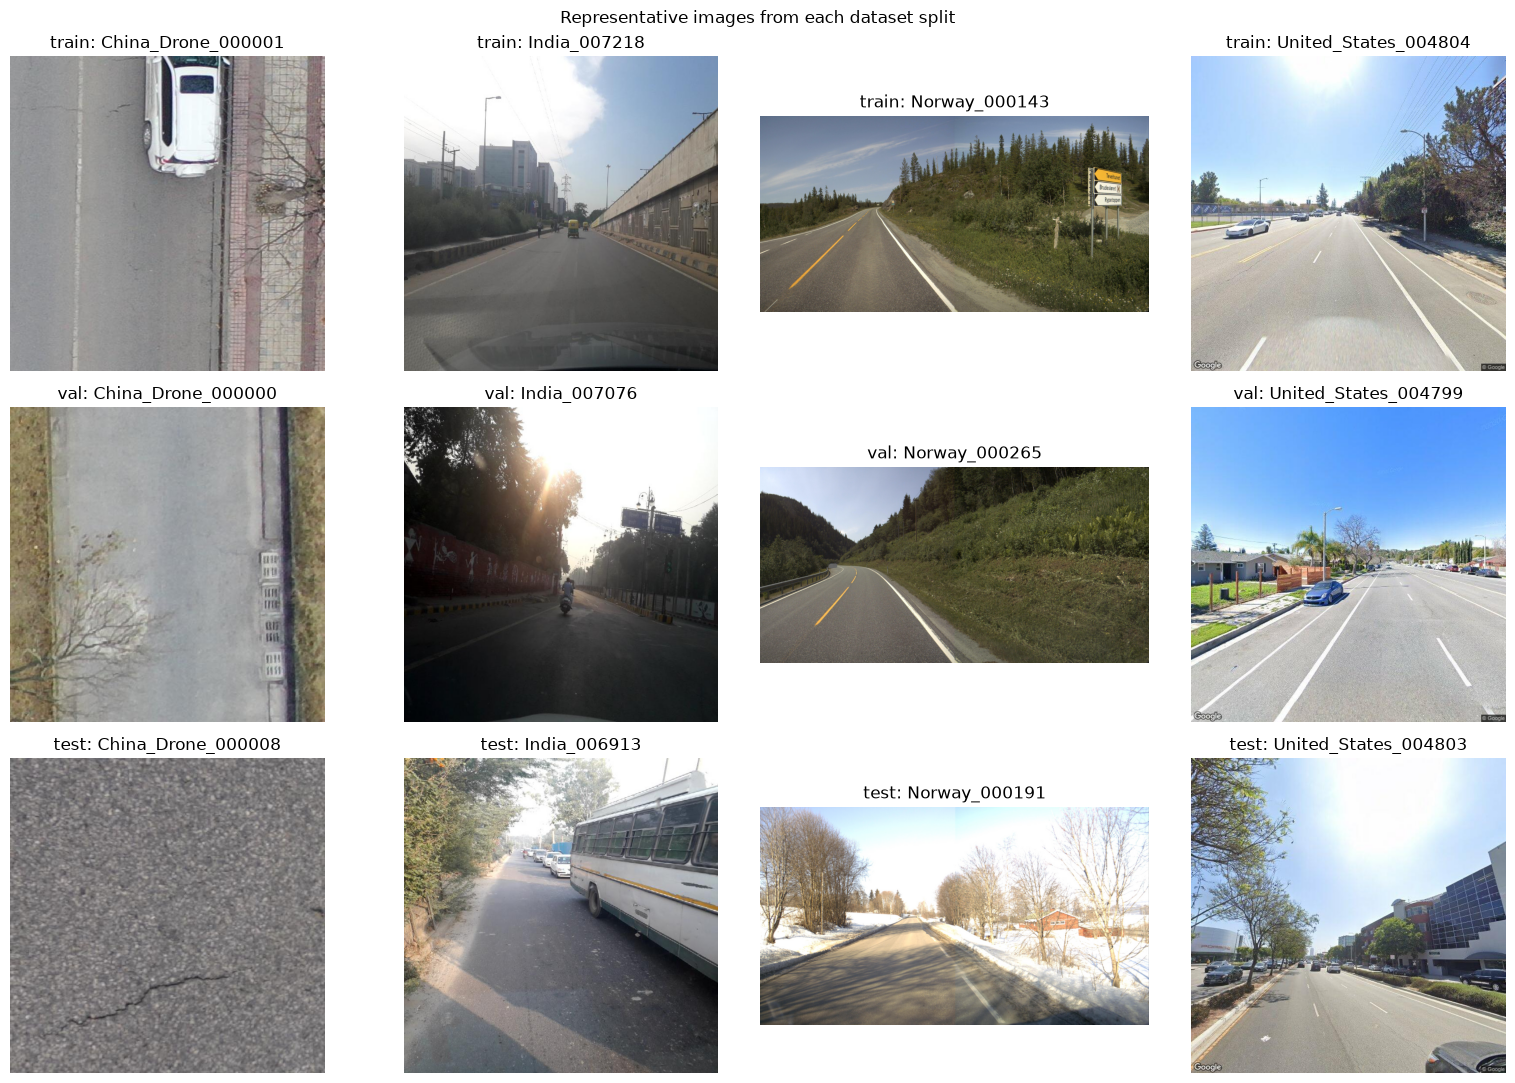

In [9]:
fig, axes = plt.subplots(len(SPLITS), 4, figsize=(16, 11))
for row, split in enumerate(SPLITS):
    paths = image_paths(split)
    sample_indices = np.linspace(0, len(paths) - 1, 4, dtype=int)
    for col, index in enumerate(sample_indices):
        axes[row, col].imshow(load_image(paths[index]))
        axes[row, col].set_title(f"{split}: {paths[index].stem}")
        axes[row, col].axis("off")
plt.suptitle("Representative images from each dataset split")
plt.tight_layout()
plt.show()


In [10]:
quality_rows = []
for split in SPLITS:
    paths = image_paths(split)
    sample_count = min(500, len(paths))
    sample_indices = np.linspace(0, len(paths) - 1, sample_count, dtype=int)
    for index in sample_indices:
        image = load_image(paths[index]).astype(np.float32)
        if image.max() > 1:
            image /= 255.0
        gray = image.mean(axis=2)
        quality_rows.append({
            "Split": split,
            "Mean Brightness": gray.mean(),
            "Brightness Std": gray.std(),
            "Dark Pixel %": (gray < 0.05).mean() * 100,
            "Bright Pixel %": (gray > 0.95).mean() * 100,
            "Edge Strength": (np.abs(np.diff(gray, axis=0)).mean() + np.abs(np.diff(gray, axis=1)).mean()) / 2,
        })

df_quality = pd.DataFrame(quality_rows)
display(df_quality.groupby("Split").agg(["mean", "median", "min", "max"]).round(4))
print(f"Image-quality sample size: {len(df_quality):,} images (up to 500 per split)")


Mean Brightness                         Brightness Std                  \
                 mean  median     min     max           mean  median     min   
Split                                                                          
test           0.5121  0.5010  0.2529  0.7971         0.2383  0.2484  0.0204   
train          0.5026  0.4973  0.2446  0.8109         0.2409  0.2569  0.0232   
val            0.4931  0.4909  0.1891  0.7751         0.2393  0.2525  0.0337   

              Dark Pixel %                       Bright Pixel %               \
          max         mean  median  min      max           mean  median  min   
Split                                                                          
test   0.3869       3.1988  0.3498  0.0  28.2342         8.0075  4.1259  0.0   
train  0.3786       3.3123  0.4835  0.0  29.5686         8.4367  4.0876  0.0   
val    0.3788       3.3277  0.4086  0.0  34.3083         7.8045  4.1914  0.0   

               Edge Strength                          
           max          mean  median     min     max  
Split                                                 
test   62.1326        0.0329  0.0264  0.0048  0.1295  
train  54.4356        0.0312  0.0249  0.0040  0.1402  
val    56.1120        0.0310  0.0252  0.0034  0.1244

Image-quality sample size: 1,500 images (up to 500 per split)


Stage 3 — Domain analysis: 
Country distributions, capture-source differences and split composition.

In [11]:
import re

def filename_metadata(path):
    tokens = path.stem.split("_")
    country = "United States" if tokens[:2] == ["United", "States"] else tokens[0]
    remainder = tokens[2:] if country == "United States" else tokens[1:]
    source_token = remainder[0] if remainder else ""
    if source_token in {"Drone", "MotorBike"}:
        source = source_token
    elif source_token and not source_token.isdigit():
        source = source_token
    else:
        source = "Unspecified/sequence"
    return country, source

metadata_rows = []
for split in SPLITS:
    for path in image_paths(split):
        country, source = filename_metadata(path)
        metadata_rows.append({
            "Split": split,
            "Image": path.stem,
            "Country": country,
            "Capture Source": source,
        })

df_metadata = pd.DataFrame(metadata_rows)
print("Metadata is inferred from image filename conventions; it is not embedded sensor metadata.")
print("\nCountry counts by split:")
display(pd.crosstab(df_metadata["Country"], df_metadata["Split"], margins=True))


Metadata is inferred from image filename conventions; it is not embedded sensor metadata.

Country counts by split:


Split,test,train,val,All
Country,,,,
China,682,3051,645,4378
Czech,436,1962,431,2829
India,1166,5368,1172,7706
Japan,1524,7432,1550,10506
Norway,1197,5708,1256,8161
United States,753,3348,704,4805
All,5758,26869,5758,38385


In [12]:
country_split = pd.crosstab(df_metadata["Country"], df_metadata["Split"], normalize="columns") * 100
print("Country composition within each split (%):")
display(country_split.round(2))

source_split = pd.crosstab(df_metadata["Capture Source"], df_metadata["Split"], margins=True)
print("Capture-source counts by split:")
display(source_split)

source_share = pd.crosstab(df_metadata["Capture Source"], df_metadata["Split"], normalize="columns") * 100
print("Capture-source composition within each split (%):")
display(source_share.round(2))


Country composition within each split (%):


Split,test,train,val
Country,,,
China,11.84,11.36,11.20
Czech,7.57,7.30,7.49
India,20.25,19.98,20.35
Japan,26.47,27.66,26.92
Norway,20.79,21.24,21.81
United States,13.08,12.46,12.23


Capture-source counts by split:


Split,test,train,val,All
Capture Source,,,,
Drone,377,1675,349,2401
MotorBike,305,1376,296,1977
Unspecified/sequence,5076,23818,5113,34007
All,5758,26869,5758,38385


Capture-source composition within each split (%):


Split,test,train,val
Capture Source,,,
Drone,6.55,6.23,6.06
MotorBike,5.30,5.12,5.14
Unspecified/sequence,88.16,88.64,88.80


In [13]:
class_split_rows = []
for split in SPLITS:
    for label_path in sorted((DATASET_PATH / split / "labels").glob("*.txt")):
        country, source = filename_metadata(label_path)
        class_ids = []
        for line in label_path.read_text(encoding="utf-8").splitlines():
            parts = line.strip().split()
            if parts:
                try:
                    class_ids.append(int(parts[0]))
                except ValueError:
                    pass
        class_split_rows.append({
            "Split": split,
            "Image": label_path.stem,
            "Country": country,
            "Capture Source": source,
            "Has Annotation": bool(class_ids),
            "Annotation Count": len(class_ids),
            "Classes": sorted(set(class_ids)),
        })

df_composition = pd.DataFrame(class_split_rows)
df_composition = df_composition.explode("Classes").dropna(subset=["Classes"])
df_composition["Classes"] = df_composition["Classes"].astype(int)
print("Annotated-image counts by country, split, and class:")
display(df_composition.groupby(["Country", "Split", "Classes"]).size().unstack("Classes", fill_value=0))

print("\nImages with at least one annotation by country and split:")
annotated = df_composition.drop_duplicates(["Country", "Split", "Image"])
display(annotated.groupby(["Country", "Split"]).size().unstack("Split", fill_value=0))


Annotated-image counts by country, split, and class:


Classes                 0     1     2     3     4
Country       Split                              
China         test    384   281   119   120    35
              train  1699  1223   536   559   155
              val     370   257    95   126    38
Czech         test    125    40    17     0    27
              train   529   203   101     0   102
              val     110    57    11     0    25
India         test    162     6   251   149   210
              train   790    44  1240   745  1086
              val     157    10   267   162   234
Japan         test    423   301   668   831   206
              train  1928  1608  3360  3943  1004
              val     446   331   686   805   180
Norway        test    370   138    46     0    34
              train  1775   723   232     0   171
              val     373   145    44     0    51
United States test    616   352   113     0    19
              train  2736  1632   507     0    81
              val     555   358   119     0    16


Images with at least one annotation by country and split:


Split,test,train,val
Country,,,
China,682,3046,645
Czech,166,746,160
India,538,2677,570
Japan,1401,6897,1414
Norway,428,2058,428
United States,753,3348,704
